Correlation between monthly percentage change in gold prices and Pewdiepie Youtube views.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

Importing gold prices and Pewdiepie youtube views onto Pandas dataframe objects.

In [2]:
goldPrices = pd.read_csv(Path('data', 'raw_data', 'gold-monthly-processed.csv'))
pewdViews = pd.read_csv(Path('data', 'raw_data', 'pewdiepie_monthly_gained_views.csv'))

Gold prices data info:

In [3]:
goldPrices.info()
goldPrices.head()

<class 'pandas.DataFrame'>
RangeIndex: 2326 entries, 0 to 2325
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    2326 non-null   str    
 1   Price   2326 non-null   float64
dtypes: float64(1), str(1)
memory usage: 36.5 KB


,Date,Price
0,1833-01-01,18.93
1,1833-02-01,18.93
2,1833-03-01,18.93
3,1833-04-01,18.93
4,1833-05-01,18.93


Pewdiepie Youtube views data info:

In [4]:
pewdViews.info()
pewdViews.head()

<class 'pandas.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 2 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Date                  35 non-null     str  
 1   Monthly Gained Views  35 non-null     int64
dtypes: int64(1), str(1)
memory usage: 692.0 bytes


,Date,Monthly Gained Views
0,2023-12,21243771
1,2024-01,16998021
2,2024-02,23694003
3,2024-03,22468328
4,2024-04,20455845


Editing the date column of both data frames to have the same format.

In [5]:
goldPrices['Date'] = pd.to_datetime(goldPrices['Date']).dt.to_period('M')
pewdViews['Date'] = pd.to_datetime(pewdViews['Date']).dt.to_period('M')

In [6]:
print(goldPrices.head())
print(pewdViews.head())

      Date  Price
0  1833-01  18.93
1  1833-02  18.93
2  1833-03  18.93
3  1833-04  18.93
4  1833-05  18.93
      Date  Monthly Gained Views
0  2023-12              21243771
1  2024-01              16998021
2  2024-02              23694003
3  2024-03              22468328
4  2024-04              20455845


Only keeping rows of gold prices that have dates in Pewdiepie Youtube views data.

In [7]:
start_date = pewdViews.iloc[0, 0]
end_date = pewdViews.iloc[len(pewdViews) - 1, 0]

goldPrices = goldPrices[(goldPrices['Date'] >= start_date) & (goldPrices['Date'] <= end_date)]

Deleting entry for 2025-08 and 2026-06 due to negative view gain on those months. Negative views gain must mean videos were made unavailable. For more accurate correlation data, it is better to ignore those values.

In [8]:
goldPrices = goldPrices[((goldPrices['Date'] != '2025-08') & (goldPrices['Date'] != '2026-06'))]
pewdViews = pewdViews[((pewdViews['Date'] != '2025-08') & (pewdViews['Date'] != '2026-06'))]

In [9]:
# Resetting order indexing.
goldPrices = goldPrices.reset_index(drop=True)
pewdViews = pewdViews.reset_index(drop=True)

Calculating percentage change of gold prices and Pewdiepie Youtube views gain.

In [10]:
goldPrices['pct'] = goldPrices['Price'].pct_change() * 100
pewdViews['pct'] = pewdViews['Monthly Gained Views'].pct_change() * 100

Storing processed data frames as csv files.

In [11]:
goldPrices.to_csv(Path('data','processed_data', 'gold_prices.csv'), index=False)
pewdViews.to_csv(Path('data', 'processed_data', 'pewd_views.csv'), index=False)

In [12]:
# Removing first row with Nan percentage change.
goldPrices = goldPrices.dropna()
pewdViews = pewdViews.dropna()

Calculating correlation between percentage change in monthly Pewdiepie Youtube view gain and percentage change in monthly gold price change from 2024-01 to 2026-10.

In [13]:
pct_correlation = pewdViews['pct'].corr(goldPrices['pct'])
print(f'The correlation is: {pct_correlation}.')

The correlation is: -0.11228712751536747.


Showing visual representation of data.

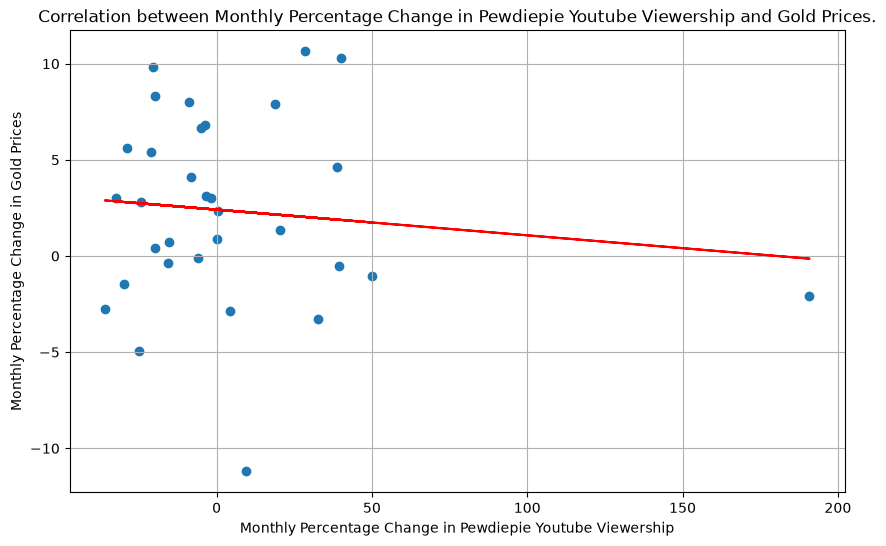

In [14]:
plt.figure(figsize=(10, 6))

x = pewdViews['pct']
y = goldPrices['pct']
plt.scatter(x, y)

# Calculating best fitting line for data.
m, c = np.polyfit(x, y, 1)
plt.plot(x, m * x + c, color='red')

plt.xlabel('Monthly Percentage Change in Pewdiepie Youtube Viewership')
plt.ylabel('Monthly Percentage Change in Gold Prices')
plt.title('Correlation between Monthly Percentage Change in Pewdiepie Youtube Viewership and Gold Prices.')
plt.grid(True)

plt.savefig(Path('figures') / 'pewdiepie_pct_gold_pct_correlation.png')
plt.show()

This shows that there is no correlation between percentage change in monthly Pewdiepie Youtube viewership and gold prices.

Using monthly percentage change for Pewdiepie's Youtube viewership creates bias for the current month if the previous month had a large viewer count.
Finding correlation between monthly gained views in Pewdiepie's Youtube channel and percentage change in monthly gold prices:

In [15]:
views_pct_correlation = pewdViews['Monthly Gained Views'].corr(goldPrices['pct'])
print(f'The correlation is: {views_pct_correlation}')

The correlation is: 0.02759149362735649


Showing visual representation of data.

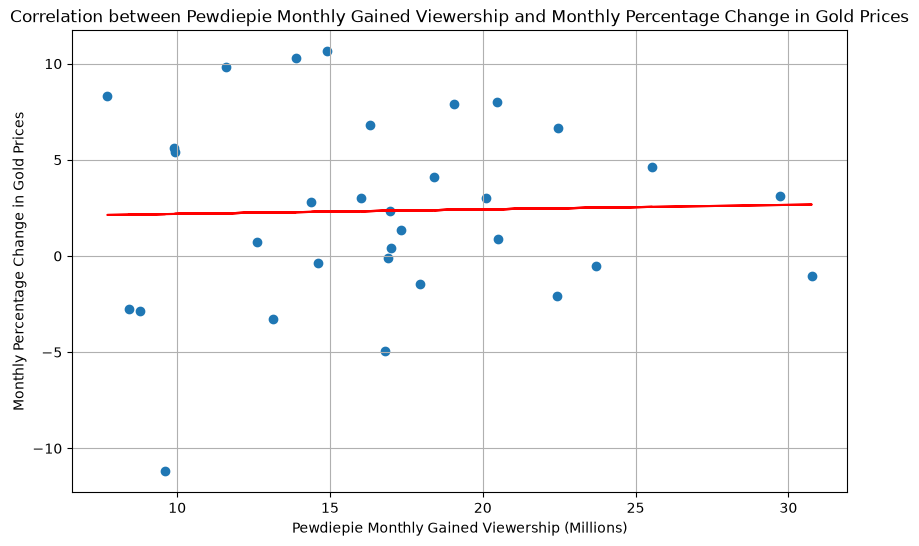

In [16]:
plt.figure(figsize=(10, 6))

x = pewdViews['Monthly Gained Views'] / 1e6 # views in millions
y = goldPrices['pct']

# Finding regression line.
m, c = np.polyfit(x, y, 1)

plt.scatter(x, y)
plt.plot(x, m*x + c, color='red')

plt.xlabel('Pewdiepie Monthly Gained Viewership (Millions)')
plt.ylabel('Monthly Percentage Change in Gold Prices')
plt.title('Correlation between Pewdiepie Monthly Gained Viewership and Monthly Percentage Change in Gold Prices')
plt.grid(True)

plt.savefig(Path('figures') / 'pewdiepie_views_gold_pct_correlation.png')
plt.show()

This shows that there is no found correlation between monthly Pewdiepie Youtube viewership gain and monthly percentage change in gold prices from the sample data.